# SupplyGraph OPME - the story in one notebook

Exploratory walk-through of the synthetic network and of the main results. It reads the generated tables
(`data/generated/full/tables`) and the analysis outputs (`reports/`), so it runs without a database.
Regenerate everything with `uv run sgraph all`.

> All business numbers are **synthetic** (seed 42). Real open data only calibrates country weights, NCM codes
> and municipality locations - see `docs/data-sources.md`.

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
T = {p.stem: pd.read_csv(p) for p in (ROOT / "data/generated/full/tables").glob("*.csv")}
M = json.loads((ROOT / "reports/metrics.json").read_text(encoding="utf-8"))
BLUE, ORANGE, GRAY = "#257de0", "#f47230", "#9c9c9c"
print({k: len(v) for k, v in sorted(T.items())})

{'bom': 1949, 'buys_from': 4574, 'can_substitute': 148, 'consumes': 26714, 'countries': 26, 'dcs': 14, 'delivered_to': 64145, 'derived_from': 75929, 'hospitals': 1400, 'items': 869, 'lots': 57972, 'manufactures': 267, 'planted_false_dual_source': 22, 'plants': 16, 'ports': 19, 'serves': 1833, 'ships_to': 98, 'stocks': 3132, 'suppliers': 244, 'supplies': 1427}


## 1. The real anchor: where Brazil imports implants from

UN Comtrade, reporter Brazil, 2024, HS 9021.10 / 9021.31 / 9021.39 / 9021.90 (ComexStat was down at extraction
time). These shares weight the countries of plants and tier-1 suppliers.

In [2]:
imp = pd.read_csv(ROOT / "data/reference/br_imports_9021_by_origin_2024.csv")
by = imp.groupby("partner_name").cif_usd.sum().sort_values(ascending=False)
print(f"Total CIF 2024: US$ {by.sum()/1e6:,.1f} M")
(by.head(10) / by.sum() * 100).round(1).rename("% of CIF").to_frame()

Total CIF 2024: US$ 693.5 M


,% of CIF
partner_name,
USA,28.5
Germany,13.1
Ireland,10.2
Mexico,9.9
Switzerland,6.7
China,5.1
France,4.9
Denmark,2.4
Italy,2.1


## 2. The synthetic network

Concentration is deliberate: deep components are assigned with linear preferential attachment, so a few tier-2
hubs emerge; some raw materials have one to three producers.

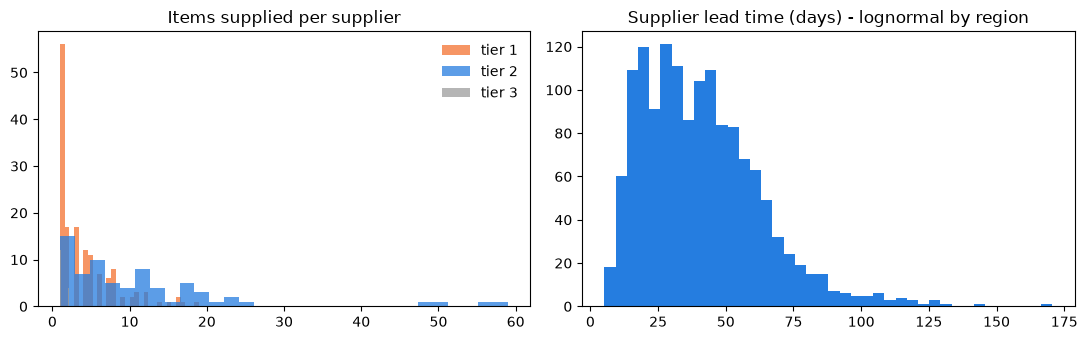

In [3]:
s = T["supplies"]
deg = s.groupby("supplier_id").size().rename("items")
tiers = T["suppliers"].set_index("id").tier
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for t, c in ((1, ORANGE), (2, BLUE), (3, GRAY)):
    ax[0].hist(deg[tiers[deg.index] == t], bins=30, alpha=0.75, color=c, label=f"tier {t}")
ax[0].set_title("Items supplied per supplier"); ax[0].legend(frameon=False)
ax[1].hist(s.lead_time_days, bins=40, color=BLUE)
ax[1].set_title("Supplier lead time (days) - lognormal by region")
plt.tight_layout()

Top 10% of hospitals = 25% of revenue (long tail by design)


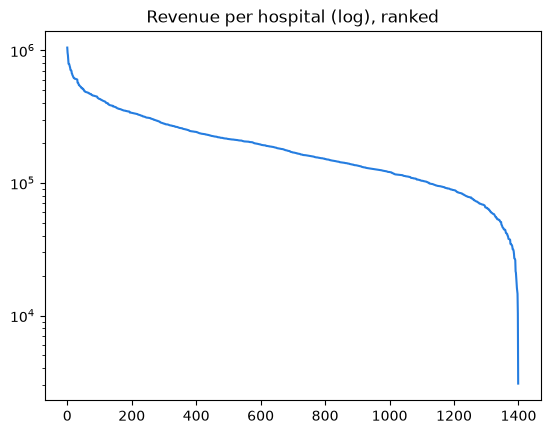

In [4]:
c = T["consumes"]
dem = c.groupby("hospital_id").revenue_month.sum().sort_values(ascending=False)
share_top10 = dem.head(int(len(dem) * 0.1)).sum() / dem.sum()
print(f"Top 10% of hospitals = {share_top10:.0%} of revenue (long tail by design)")
dem.reset_index(drop=True).plot(logy=True, color=BLUE, title="Revenue per hospital (log), ranked");

## 3. The false dual-source (section 9B)

A level-1 component bought from two or three tier-1 suppliers *looks* safe in the ERP. In the graph we follow
each supplier's own sub-tier purchases (BOM-consistent `BUYS_FROM` chains) and ask whether all of them depend
100% on the same upstream supplier.

In [5]:
b = M["B"]
print(f"{b['false_dual_items']} of {b['multi_sourced_l1_items']} multi-sourced items ({b['false_dual_pct']}%) "
      f"converge on one upstream supplier -> {b['revenue_exposed_pct']}% of revenue")
pd.read_csv(ROOT / "reports/analytics/B1_hidden_suppliers_ranking.csv").head(10)

66 of 224 multi-sourced items (29.5%) converge on one upstream supplier -> 53.3% of revenue


,hidden_supplier,hidden_tier,hidden_country,items
0,S-T2-049,2,CN,15
1,S-T2-007,2,DE,10
2,S-T2-055,2,IT,9
3,S-T2-054,2,US,8
4,S-T3-018,3,GB,7
5,S-T3-024,3,US,6
6,S-T2-044,2,CH,6
7,S-T2-036,2,CH,6
8,S-T3-007,3,US,6
9,S-T2-023,2,MX,5


## 4. ERP view vs graph view by country (section 9C)

Hard dependency = revenue of implants that have at least one input sourced 100% from the country.

In [6]:
geo = pd.read_csv(ROOT / "reports/analytics/C2_geo_hard_dependency.csv").head(10)
geo.assign(hidden_pp=geo.graph_pct - geo.erp_pct)

,iso2,country,erp_pct,graph_pct,hidden_pp
0,US,United States,37.1,79.8,42.7
1,BR,Brazil,60.9,68.8,7.9
2,CN,China,0.4,43.6,43.2
3,FR,France,0.8,41.0,40.2
4,DE,Germany,9.0,32.4,23.4
5,SG,Singapore,22.9,22.9,0.0
6,IE,Ireland,15.2,15.2,0.0
7,MX,Mexico,0.1,13.7,13.6
8,CH,Switzerland,3.3,12.9,9.6
9,CR,Costa Rica,7.5,7.5,0.0


![ERP vs graph](../docs/img/geo_erp_vs_graph.png)

## 5. Who can really stop the business? (section 9D, TTS x TTR)

In [7]:
r = pd.read_csv(ROOT / "reports/analytics/D_supplier_risk_ranking.csv")
print("Tier of the 10 suppliers with the highest revenue at risk:", r.head(10).tier.tolist())
print("Position of the first tier-1 supplier:", int(r.index[r.tier == 1][0]) + 1)
r.head(10)[["supplier_id", "tier", "country", "revenue_at_risk", "hospitals_affected", "first_stockout_day"]]

Tier of the 10 suppliers with the highest revenue at risk: [3, 3, 3, 3, 3, 2, 2, 3, 3, 3]
Position of the first tier-1 supplier: 74


,supplier_id,tier,country,revenue_at_risk,hospitals_affected,first_stockout_day
0,S-T3-003,3,US,2.421522e+08,1400,34.8
1,S-T3-007,3,US,2.031750e+08,1400,34.8
2,S-T3-020,3,CH,2.031495e+08,1394,39.9
3,S-T3-021,3,FR,1.597300e+08,1400,34.8
4,S-T3-015,3,CN,1.438395e+08,1394,39.9
5,S-T2-007,2,DE,1.008043e+08,1399,44.5
6,S-T2-036,2,CH,1.005656e+08,1400,39.9
7,S-T3-022,3,FR,9.659262e+07,1078,54.5
8,S-T3-019,3,JP,9.079887e+07,1368,46.4
9,S-T3-017,3,CH,8.999964e+07,1142,54.5


![TTS x TTR](../docs/img/tts_vs_ttr_worst_supplier.png)

## 6. Recall in milliseconds (section 9E)

In [8]:
e = M["E"]
print(f"Raw lot {e['lot_id']}: {e['finished_lots']} implant lots, {e['units_implanted_or_delivered']:,} units "
      f"delivered to {e['hospitals']} hospitals in {e['ufs']} states, {e['units_in_stock_to_quarantine']} units "
      f"to quarantine. Forward trace: {e['forward_ms']:.0f} ms, backward: {e['backward_ms']:.0f} ms")

Raw lot RM-TI64-L0043: 105 implant lots, 5,881 units delivered to 180 hospitals in 26 states, 684 units to quarantine. Forward trace: 19 ms, backward: 3 ms


## 7. Graph algorithms and the criticality index (section 10)

In [9]:
g = M["GDS"]
print("Leiden:", g["leiden"], "| vs purchasing categories:", g["communities_vs_categories"])
pd.DataFrame(M["criticality"]["sensitivity"])

Leiden: {'communities': 4, 'modularity': 0.5324251334994661} | vs purchasing categories: {'items': 851, 'communities': 4, 'purity_vs_category': 0.443, 'purity_vs_family': 1.0, 'nmi_vs_category': 0.609}


,scenario,spearman_vs_base,top10_overlap,top1
0,revenue_heavy,0.980,8,S-T3-003
1,structure_heavy,0.969,8,S-T2-054
2,risk_heavy,0.900,8,S-T2-007
3,equal,0.986,9,S-T2-007


## 8. Graph vs relational benchmark (section 11)

In [10]:
bm = pd.read_csv(ROOT / "reports/benchmark/results.csv")
bm.pivot_table(index=["size", "bom_depth"], columns="question", values="speedup_graph").round(2)

question        Q1 BOM explosion (all implants)  \
size bom_depth                                    
L    3                                     0.22   
     5                                     0.11   
     7                                     0.06   
S    3                                     0.68   
     5                                     0.24   
     7                                     0.13   

question        Q2 false dual-source (strict)  Q3 blast radius, TTR 60 d  
size bom_depth                                                            
L    3                                   0.11                       0.19  
     5                                   0.05                       0.02  
     7                                   0.03                       0.02  
S    3                                   0.43                       0.89  
     5                                   0.15                       0.20  
     7                                   0.13                       0.06

`speedup_graph` > 1 would mean Neo4j was faster. It is below 1 everywhere: DuckDB won all 18 cases on these
whole-network batch questions. The graph's case is expressiveness (3-6x fewer lines), interactive point queries and
graph algorithms - see `docs/benchmarks.md` for the full reading.